# 📱 AppScope — Unveiling the Android App Market

### Google Play Store Data Analysis and Review Sentiment

**Domain:** Data Analytics and Natural Language Processing (NLP)  
**Internship Task:** Level 2 — Task 4

**Objective:** Analyze Google Play Store application data and user reviews to discover category trends, ratings, installation patterns, pricing distributions, and customer sentiment.

**Technologies:** Python, NumPy, CSV, VADER Sentiment Analysis, JupyterLab, and SVG visualizations.

**Key Areas:** Data Cleaning, Exploratory Data Analysis, Sentiment Classification, Visualization, and Business Insights.

In [1]:
import sys
print("Python version:", sys.version)

packages = ["numpy", "pandas", "matplotlib", "seaborn",
            "sklearn", "IPython"]

for package in packages:
    try:
        module = __import__(package)
        print(package, "OK", getattr(module, "__version__", ""))
    except Exception as error:
        print(package, "ERROR:", str(error)[:180])

Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
numpy OK 1.23.5
pandas OK 1.5.3
matplotlib OK 3.7.1
seaborn OK 0.12.2
sklearn OK 1.2.2
IPython OK 9.17.1


In [1]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
print("VADER sentiment analysis is ready!")

try:
    import plotly.express as px
    print("Plotly is ready!")
except Exception as error:
    print("Plotly unavailable:", error)

VADER sentiment analysis is ready!
Plotly is ready!


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Data folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for file in DATA_DIR.iterdir():
        print(file.name)

Project folder: C:\Users\Santhya S\Downloads\DataAnalytics-Level2-Task4-AppScope
Data folder exists: True
googleplaystore.csv
googleplaystore_user_reviews.csv
license.txt


In [3]:
import pandas as pd

apps = pd.read_csv(DATA_DIR / "googleplaystore.csv")
reviews = pd.read_csv(DATA_DIR / "googleplaystore_user_reviews.csv")

print("Apps dataset shape:", apps.shape)
print("Reviews dataset shape:", reviews.shape)

display(apps.head())
display(reviews.head())

Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [4]:
# Check column data types
print("APP DATA TYPES")
print(apps.dtypes)

print("\nREVIEW DATA TYPES")
print(reviews.dtypes)

# Check missing values
print("\nMISSING VALUES IN APPS")
display(apps.isnull().sum())

print("\nMISSING VALUES IN REVIEWS")
display(reviews.isnull().sum())

# Check duplicate records
print("\nDUPLICATE APP ROWS:", apps.duplicated().sum())
print("DUPLICATE REVIEW ROWS:", reviews.duplicated().sum())

APP DATA TYPES
App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

REVIEW DATA TYPES
App                        object
Translated_Review          object
Sentiment                  object
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

MISSING VALUES IN APPS


App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


MISSING VALUES IN REVIEWS


App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


DUPLICATE APP ROWS: 483
DUPLICATE REVIEW ROWS: 33616


In [5]:
import pandas as pd
import numpy as np

# Work on copies so the original loaded data remains available
apps_clean = apps.copy()
reviews_clean = reviews.copy()

# Remove duplicate records
apps_clean = apps_clean.drop_duplicates()

# Clean numeric columns
apps_clean["Reviews"] = pd.to_numeric(
    apps_clean["Reviews"], errors="coerce"
)

apps_clean["Installs"] = pd.to_numeric(
    apps_clean["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

apps_clean["Price"] = pd.to_numeric(
    apps_clean["Price"]
    .astype(str)
    .str.replace("$", "", regex=False),
    errors="coerce"
)

# Convert app size to megabytes
def convert_size(value):
    value = str(value).strip()

    if value in ["nan", "NaN", "Varies with device"]:
        return np.nan

    try:
        if value.endswith("M"):
            return float(value[:-1])
        elif value.endswith("k"):
            return float(value[:-1]) / 1024
        else:
            return np.nan
    except ValueError:
        return np.nan

apps_clean["Size_MB"] = apps_clean["Size"].apply(convert_size)

# Ensure ratings are numeric
apps_clean["Rating"] = pd.to_numeric(
    apps_clean["Rating"], errors="coerce"
)

# Remove impossible rating values
apps_clean.loc[
    ~apps_clean["Rating"].between(1, 5),
    "Rating"
] = np.nan

# Normalize app type
apps_clean["Type"] = apps_clean["Type"].astype("string").str.strip()

# Remove rows with missing essential fields
apps_clean = apps_clean.dropna(
    subset=["App", "Category", "Installs", "Price"]
)

# Show cleaning results
print("Original app rows:", len(apps))
print("Cleaned app rows:", len(apps_clean))
print("Duplicates remaining:", apps_clean.duplicated().sum())
print("\nMissing values after cleaning:")
display(apps_clean.isnull().sum())

Original app rows: 10841
Cleaned app rows: 10357
Duplicates remaining: 0

Missing values after cleaning:


App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1526
dtype: int64

In [6]:
# Remove duplicate review records
reviews_clean = reviews_clean.drop_duplicates()

# Remove rows without usable review text
reviews_clean = reviews_clean.dropna(
    subset=["Translated_Review"]
)

reviews_clean["Translated_Review"] = (
    reviews_clean["Translated_Review"].astype(str).str.strip()
)

reviews_clean = reviews_clean[
    reviews_clean["Translated_Review"] != ""
].copy()

# Check review data
print("Original review rows:", len(reviews))
print("Cleaned review rows:", len(reviews_clean))
print("Missing review texts:", reviews_clean["Translated_Review"].isna().sum())
print("\nSample cleaned reviews:")
display(reviews_clean[["App", "Translated_Review"]].head())

Original review rows: 64295
Cleaned review rows: 29692
Missing review texts: 0

Sample cleaned reviews:


,App,Translated_Review
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...
1,10 Best Foods for You,This help eating healthy exercise regular basis
3,10 Best Foods for You,Works great especially going grocery store
4,10 Best Foods for You,Best idea us
5,10 Best Foods for You,Best way


In [7]:
from pathlib import Path

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

apps_clean.to_csv(
    OUTPUT_DIR / "cleaned_play_store_apps.csv",
    index=False
)

reviews_clean.to_csv(
    OUTPUT_DIR / "cleaned_user_reviews.csv",
    index=False
)

print("Cleaned datasets saved in:", OUTPUT_DIR)

Cleaned datasets saved in: C:\Users\Santhya S\Downloads\DataAnalytics-Level2-Task4-AppScope\outputs


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count apps in each category
category_counts = (
    apps_clean["Category"]
    .value_counts()
    .sort_values(ascending=False)
)

# Display the 10 largest categories
print("Top 10 categories by number of apps:")
display(category_counts.head(10).to_frame("Number of Apps"))

# Plot category distribution
plt.figure(figsize=(14, 7))
sns.barplot(
    x=category_counts.head(15).values,
    y=category_counts.head(15).index,
    color="steelblue"
)

plt.title("Top 15 Google Play Store Categories by App Count")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "01_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Top 10 categories by number of apps:


,Number of Apps
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408
PRODUCTIVITY,407
PERSONALIZATION,388
LIFESTYLE,373
COMMUNICATION,366
FINANCE,360


<Figure size 1400x700 with 1 Axes>

Number of apps with valid ratings: 8892
Average app rating: 4.19
Median app rating: 4.3


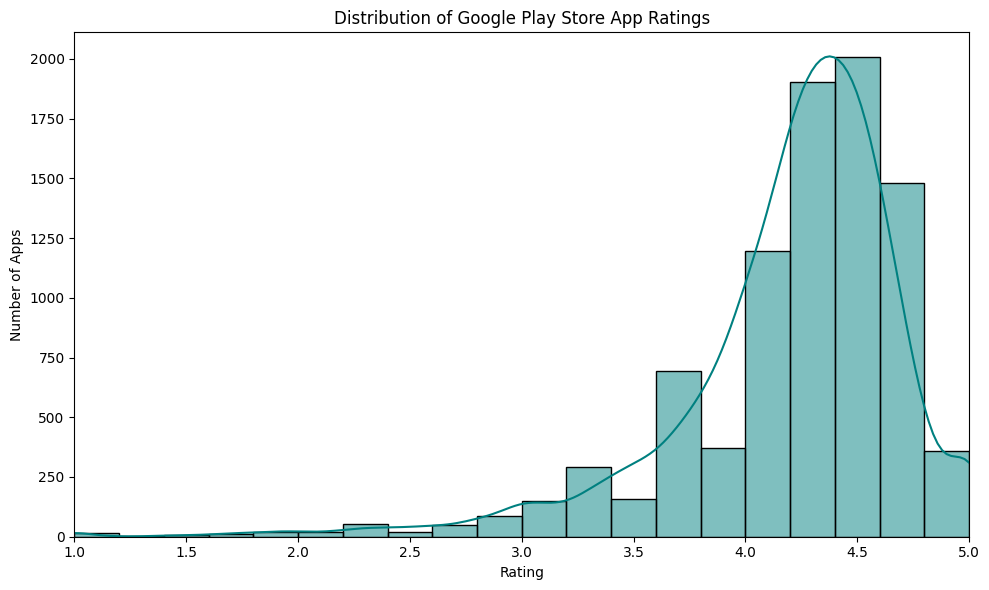

In [9]:
# Overall rating distribution
rating_data = apps_clean["Rating"].dropna()

print("Number of apps with valid ratings:", len(rating_data))
print("Average app rating:", round(rating_data.mean(), 2))
print("Median app rating:", round(rating_data.median(), 2))

plt.figure(figsize=(10, 6))
sns.histplot(rating_data, bins=20, kde=True, color="teal")

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.xlim(1, 5)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [10]:
category_ratings = (
    apps_clean.groupby("Category")["Rating"]
    .agg(["mean", "count"])
    .dropna()
    .sort_values("mean", ascending=False)
)

print("Top categories by average rating:")
display(category_ratings.head(10).round(2))

print("Lowest-rated categories with at least 20 rated apps:")
display(
    category_ratings[category_ratings["count"] >= 20]
    .sort_values("mean")
    .head(10)
    .round(2)
)

Top categories by average rating:


,mean,count
Category,,
EVENTS,4.44,45
EDUCATION,4.38,129
ART_AND_DESIGN,4.36,62
BOOKS_AND_REFERENCE,4.35,177
PERSONALIZATION,4.33,310
PARENTING,4.30,50
GAME,4.28,1074
BEAUTY,4.28,42
HEALTH_AND_FITNESS,4.26,262


Lowest-rated categories with at least 20 rated apps:


,mean,count
Category,,
DATING,3.97,159
TOOLS,4.05,734
MAPS_AND_NAVIGATION,4.05,124
VIDEO_PLAYERS,4.06,160
TRAVEL_AND_LOCAL,4.09,205
LIFESTYLE,4.10,305
BUSINESS,4.10,270
FINANCE,4.13,317
NEWS_AND_MAGAZINES,4.13,214


Apps with valid ratings: 8892
Average rating: 4.19
Median rating: 4.3


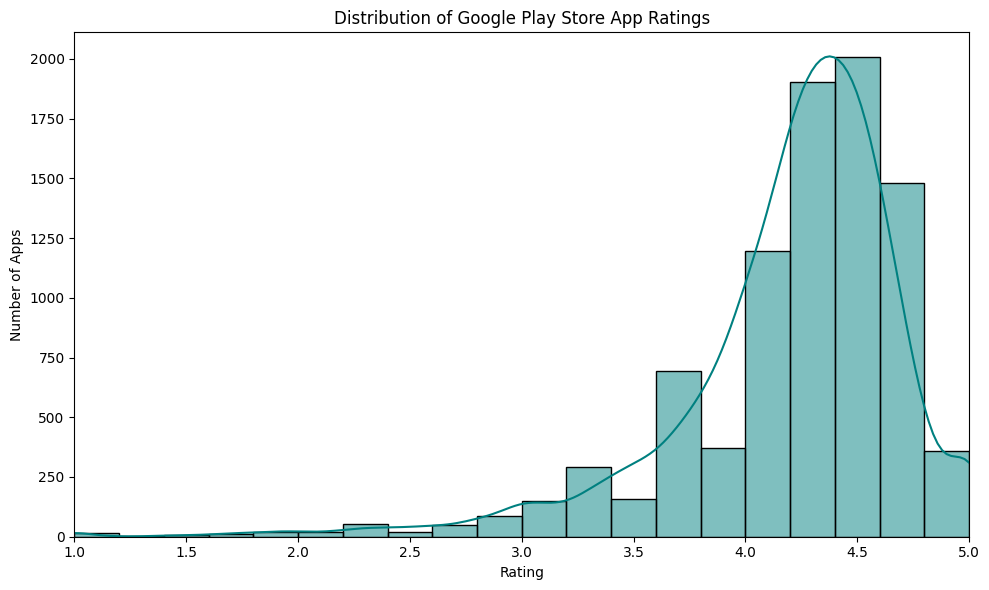

Top 10 categories by average rating:


,mean,count
Category,,
EVENTS,4.44,45
EDUCATION,4.38,129
ART_AND_DESIGN,4.36,62
BOOKS_AND_REFERENCE,4.35,177
PERSONALIZATION,4.33,310
PARENTING,4.30,50
GAME,4.28,1074
BEAUTY,4.28,42
HEALTH_AND_FITNESS,4.26,262


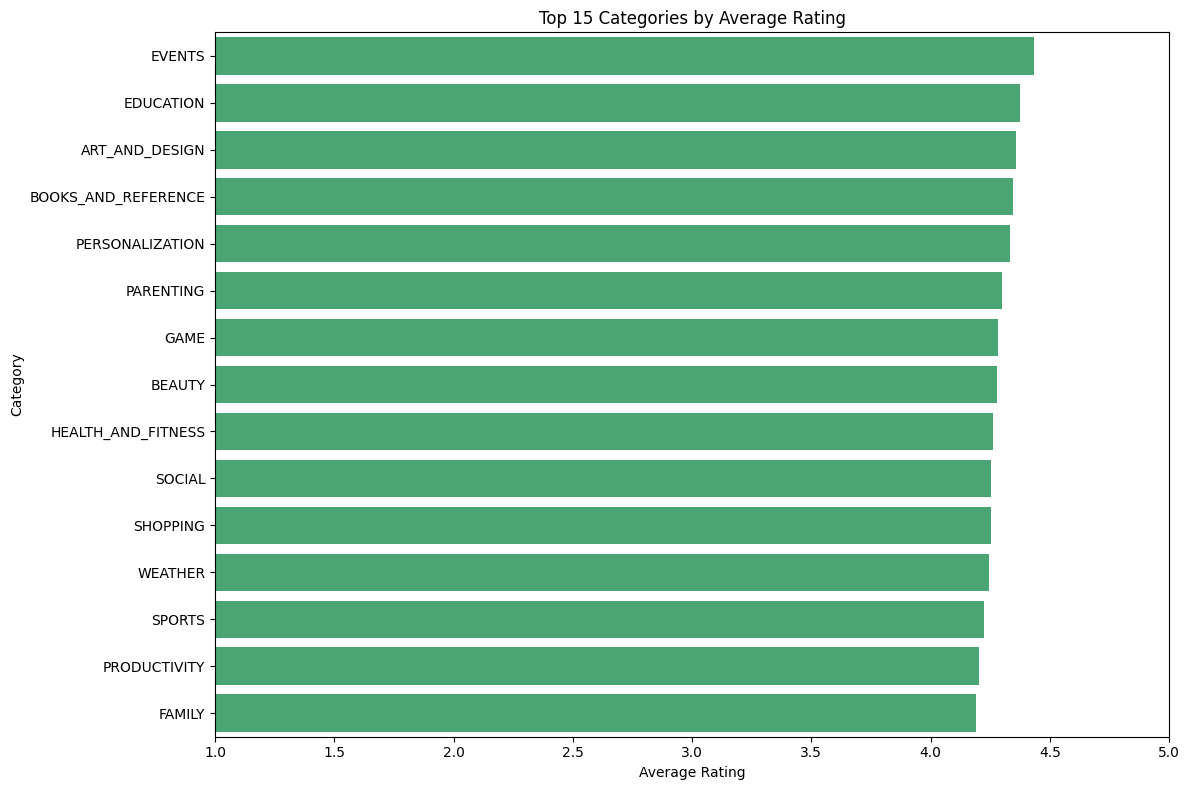

In [11]:
# Overall rating distribution
rating_data = apps_clean["Rating"].dropna()

print("Apps with valid ratings:", len(rating_data))
print("Average rating:", round(rating_data.mean(), 2))
print("Median rating:", round(rating_data.median(), 2))

plt.figure(figsize=(10, 6))
sns.histplot(rating_data, bins=20, kde=True, color="teal")
plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.xlim(1, 5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_rating_distribution.png", dpi=300)
plt.show()

# Average rating by category
category_ratings = (
    apps_clean.groupby("Category")["Rating"]
    .agg(["mean", "count"])
    .dropna()
    .sort_values("mean", ascending=False)
)

print("Top 10 categories by average rating:")
display(category_ratings.head(10).round(2))

# Require at least 20 rated apps for a more meaningful comparison
eligible_categories = category_ratings[
    category_ratings["count"] >= 20
].sort_values("mean", ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=eligible_categories.head(15)["mean"].values,
    y=eligible_categories.head(15).index,
    color="mediumseagreen"
)
plt.title("Top 15 Categories by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(1, 5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_average_rating_by_category.png", dpi=300)
plt.show()

Apps available for size/install analysis: 8817
Spearman correlation: 0.342


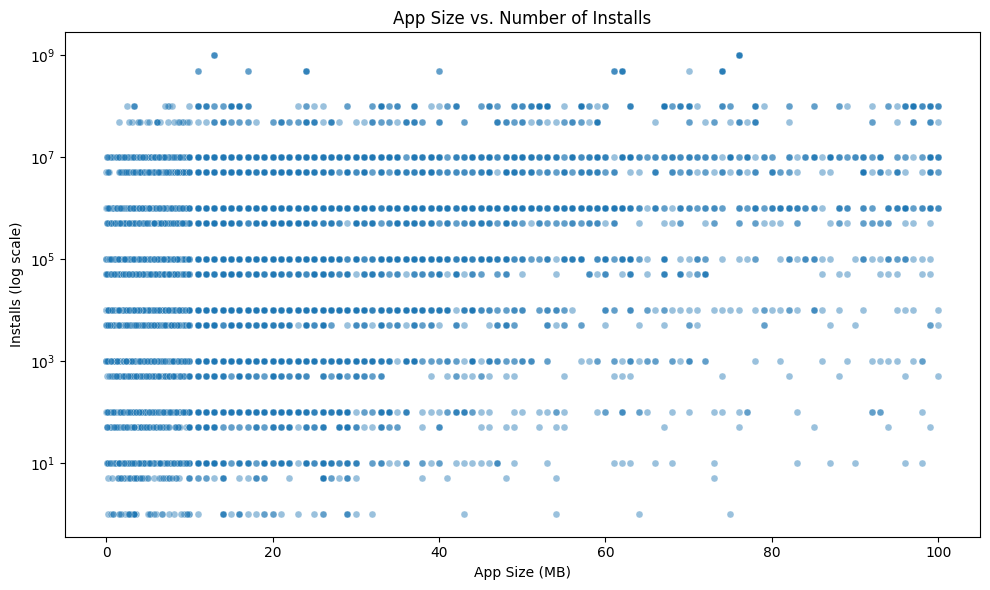

In [12]:
# Select rows with valid size and install values
size_data = apps_clean.dropna(
    subset=["Size_MB", "Installs"]
).copy()

size_data = size_data[
    (size_data["Size_MB"] > 0) &
    (size_data["Installs"] > 0)
]

print("Apps available for size/install analysis:", len(size_data))

correlation = size_data["Size_MB"].corr(
    size_data["Installs"], method="spearman"
)

print("Spearman correlation:", round(correlation, 3))

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=size_data,
    x="Size_MB",
    y="Installs",
    alpha=0.45,
    s=25
)
plt.yscale("log")
plt.title("App Size vs. Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Installs (log scale)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_size_vs_installs.png", dpi=300)
plt.show()

Free vs. paid apps:


,Number of Apps
Free,9592
Paid,765


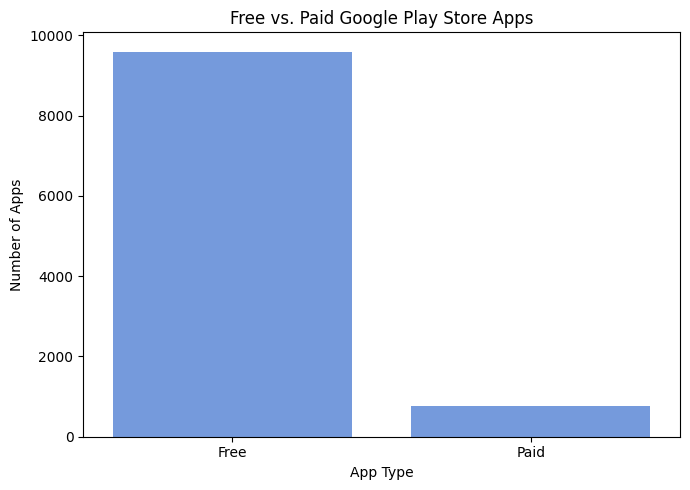

Number of paid apps: 765
Median paid-app price: 2.99


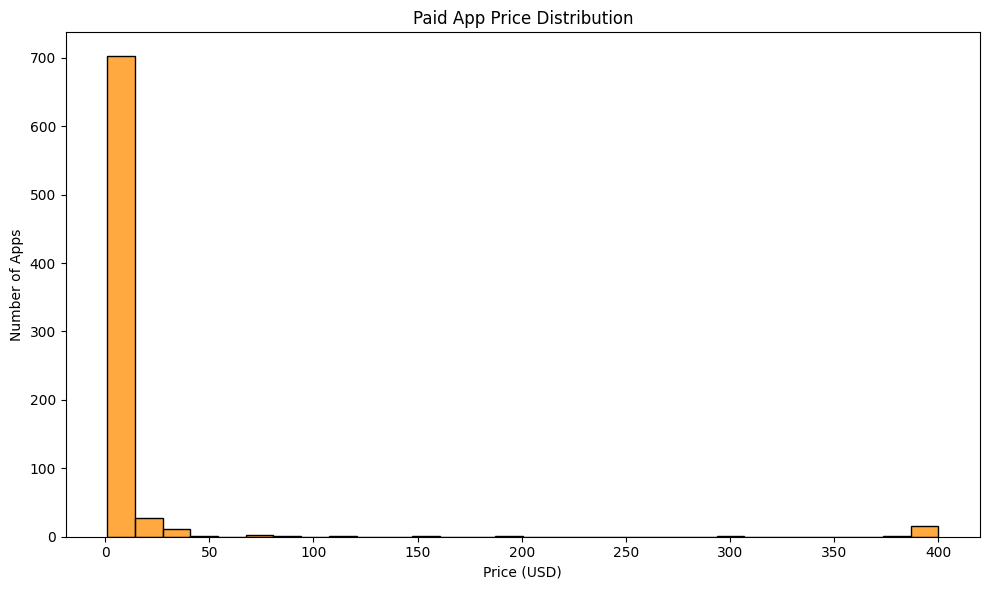

In [13]:
# Count free and paid apps
apps_clean["App_Type"] = np.where(
    apps_clean["Price"] > 0, "Paid", "Free"
)

type_counts = apps_clean["App_Type"].value_counts()

print("Free vs. paid apps:")
display(type_counts.to_frame("Number of Apps"))

plt.figure(figsize=(7, 5))
sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    color="cornflowerblue"
)
plt.title("Free vs. Paid Google Play Store Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_free_vs_paid.png", dpi=300)
plt.show()

# Paid app price distribution
paid_apps = apps_clean[apps_clean["Price"] > 0]

print("Number of paid apps:", len(paid_apps))
print("Median paid-app price:", round(paid_apps["Price"].median(), 2))

plt.figure(figsize=(10, 6))
sns.histplot(paid_apps["Price"], bins=30, color="darkorange")
plt.title("Paid App Price Distribution")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_paid_app_prices.png", dpi=300)
plt.show()

Top categories by estimated paid-app revenue:


,Estimated Revenue (USD)
Category,
FAMILY,1.857803e+08
LIFESTYLE,5.758394e+07
GAME,4.098764e+07
FINANCE,2.572668e+07
PHOTOGRAPHY,8.942768e+06
MEDICAL,8.456536e+06
PERSONALIZATION,7.786948e+06
TOOLS,5.464821e+06
SPORTS,4.706212e+06


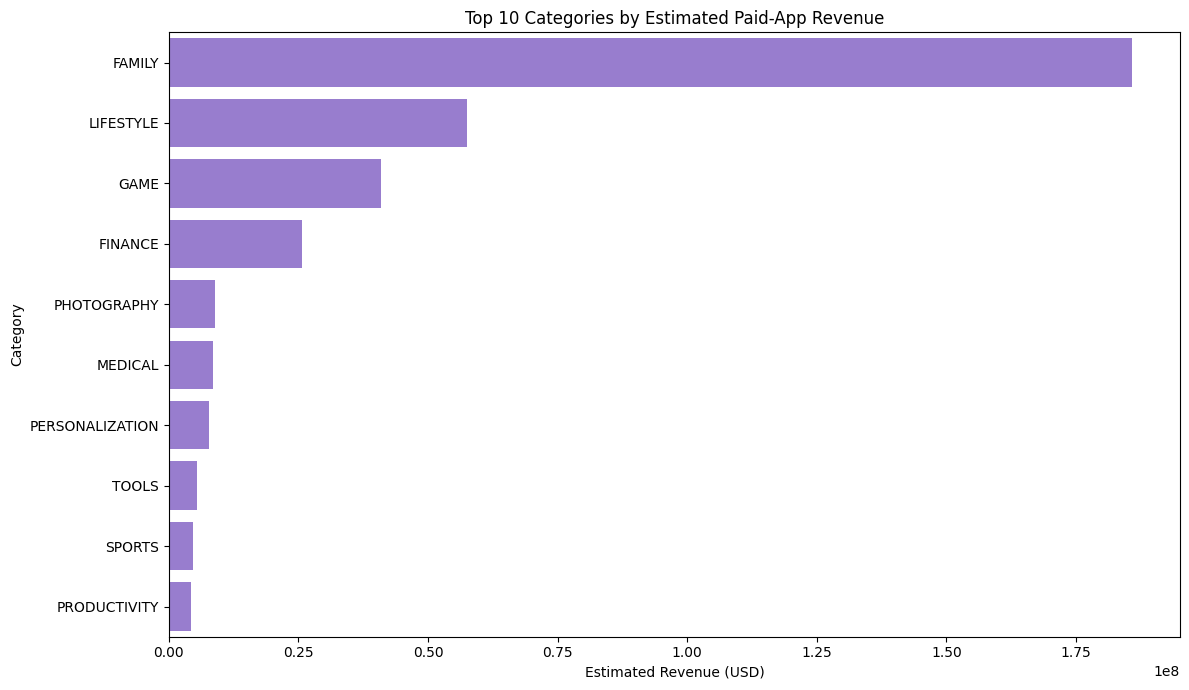

In [14]:
paid_apps = apps_clean[apps_clean["Price"] > 0].copy()
paid_apps["Estimated_Revenue"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

revenue_by_category = (
    paid_apps.groupby("Category")["Estimated_Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top categories by estimated paid-app revenue:")
display(revenue_by_category.head(10).to_frame("Estimated Revenue (USD)"))

plt.figure(figsize=(12, 7))
sns.barplot(
    x=revenue_by_category.head(10).values,
    y=revenue_by_category.head(10).index,
    color="mediumpurple"
)
plt.title("Top 10 Categories by Estimated Paid-App Revenue")
plt.xlabel("Estimated Revenue (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_revenue_by_category.png", dpi=300)
plt.show()

Review sentiment distribution:


,Number of Reviews
Positive,20195
Negative,5867
Neutral,3630


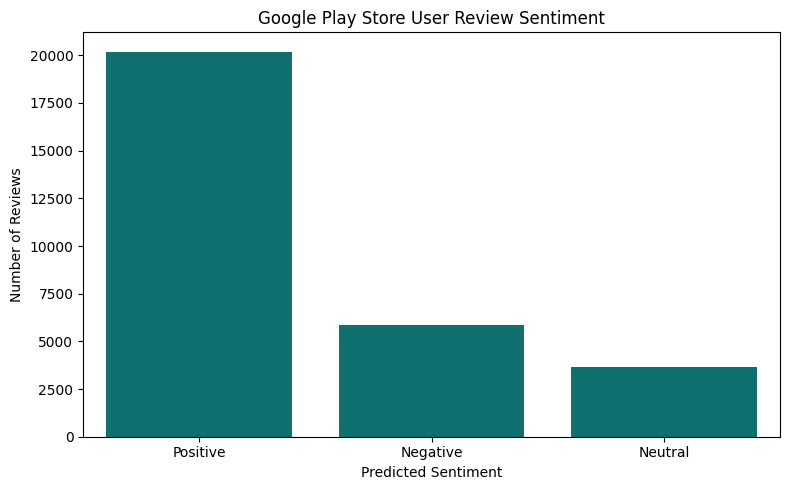

In [15]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews_sentiment = reviews_clean.copy()

reviews_sentiment["Predicted_Sentiment"] = (
    reviews_sentiment["Translated_Review"]
    .apply(classify_sentiment)
)

sentiment_counts = (
    reviews_sentiment["Predicted_Sentiment"]
    .value_counts()
)

print("Review sentiment distribution:")
display(sentiment_counts.to_frame("Number of Reviews"))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    color="teal"
)
plt.title("Google Play Store User Review Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_review_sentiment.png", dpi=300)
plt.show()

Categories with highest positive sentiment:


Predicted_Sentiment,Negative,Neutral,Positive
Category,,,
COMICS,2.2,11.1,86.7
AUTO_AND_VEHICLES,4.9,12.7,82.3
EVENTS,12.2,7.7,80.1
EDUCATION,10.4,10.9,78.7
HEALTH_AND_FITNESS,13.6,7.9,78.5
ART_AND_DESIGN,13.3,11.9,74.9
FOOD_AND_DRINK,15.3,11.0,73.8
PARENTING,10.5,16.0,73.4
GAME,21.0,6.0,73.0


Categories with highest negative sentiment:


Predicted_Sentiment,Negative,Neutral,Positive
Category,,,
VIDEO_PLAYERS,31.9,11.3,56.7
SOCIAL,31.5,13.5,55.1
ENTERTAINMENT,26.8,14.4,58.8
NEWS_AND_MAGAZINES,25.2,17.2,57.6
COMMUNICATION,25.1,12.9,62.0
FINANCE,24.2,10.0,65.9
DATING,22.3,14.7,63.0
SPORTS,22.0,11.3,66.7
TRAVEL_AND_LOCAL,21.8,13.8,64.4


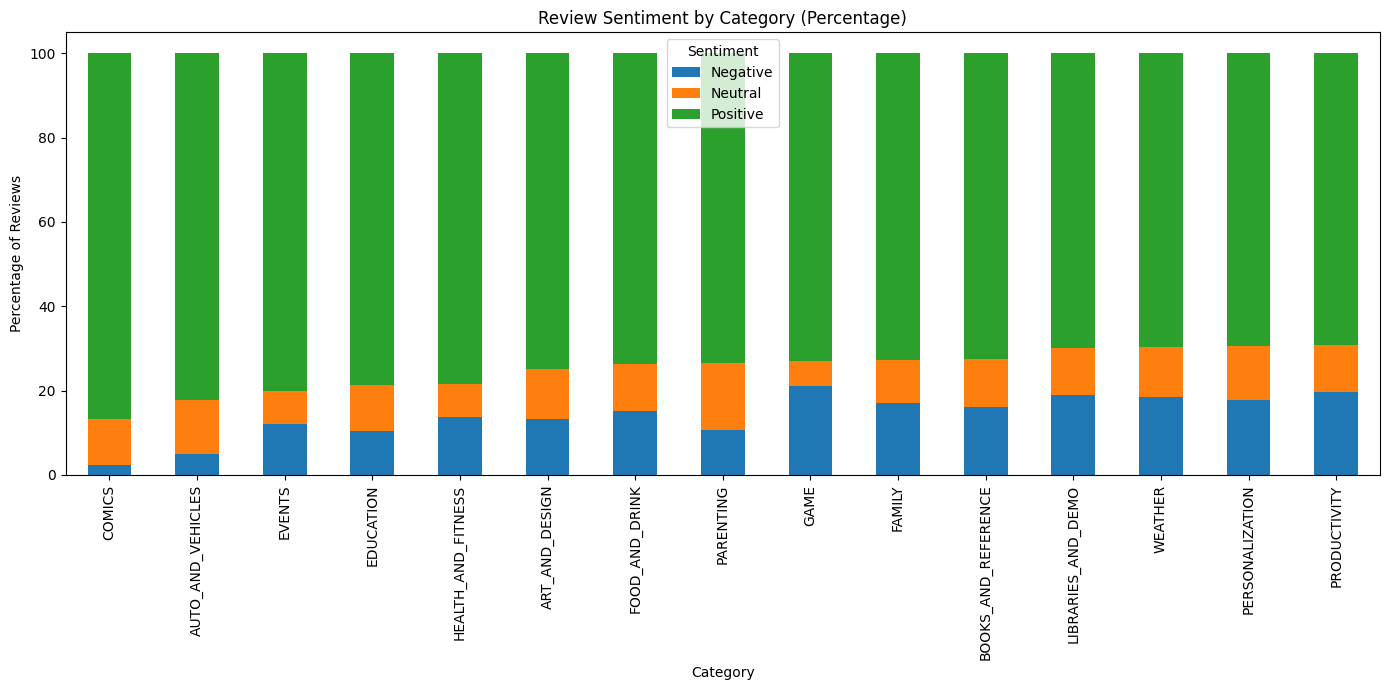

In [16]:
# Attach category information to reviews
app_categories = apps_clean[["App", "Category"]].drop_duplicates(
    subset=["App"]
)

sentiment_by_category = reviews_sentiment.merge(
    app_categories,
    on="App",
    how="left"
)

sentiment_by_category = sentiment_by_category.dropna(
    subset=["Category"]
)

# Calculate percentage of positive, negative, and neutral reviews
sentiment_percentages = pd.crosstab(
    sentiment_by_category["Category"],
    sentiment_by_category["Predicted_Sentiment"],
    normalize="index"
) * 100

# Focus on categories with at least 30 analyzed reviews
review_category_counts = sentiment_by_category.groupby(
    "Category"
).size()

eligible = sentiment_percentages.loc[
    review_category_counts[review_category_counts >= 30].index
]

if "Positive" in eligible.columns:
    print("Categories with highest positive sentiment:")
    display(eligible.sort_values("Positive", ascending=False).head(10).round(1))

if "Negative" in eligible.columns:
    print("Categories with highest negative sentiment:")
    display(eligible.sort_values("Negative", ascending=False).head(10).round(1))

eligible.sort_values(
    "Positive", ascending=False
).head(15).plot(
    kind="bar", stacked=True, figsize=(14, 7)
)

plt.title("Review Sentiment by Category (Percentage)")
plt.xlabel("Category")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_sentiment_by_category.png", dpi=300)
plt.show()

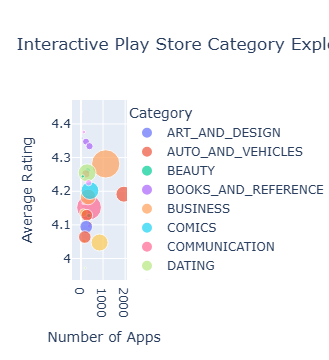

In [17]:
import plotly.express as px

interactive_data = (
    apps_clean.groupby("Category")
    .agg(
        App_Count=("App", "count"),
        Average_Rating=("Rating", "mean"),
        Total_Installs=("Installs", "sum")
    )
    .reset_index()
)

fig = px.scatter(
    interactive_data,
    x="App_Count",
    y="Average_Rating",
    size="Total_Installs",
    color="Category",
    hover_name="Category",
    title="Interactive Play Store Category Explorer",
    labels={
        "App_Count": "Number of Apps",
        "Average_Rating": "Average Rating",
        "Total_Installs": "Total Recorded Installs"
    }
)

fig.show()
fig.write_html(OUTPUT_DIR / "10_interactive_category_explorer.html")

In [18]:
reviews_sentiment.to_csv(
    OUTPUT_DIR / "reviews_with_predicted_sentiment.csv",
    index=False
)

sentiment_percentages.to_csv(
    OUTPUT_DIR / "sentiment_percentages_by_category.csv"
)

revenue_by_category.to_csv(
    OUTPUT_DIR / "estimated_revenue_by_category.csv"
)

print("Analysis outputs saved to:", OUTPUT_DIR)

Analysis outputs saved to: C:\Users\Santhya S\Downloads\DataAnalytics-Level2-Task4-AppScope\outputs


# 📊 Insights and Conclusion

## Key Insights

### 1. App Category Distribution and Market Saturation
The category analysis revealed that **[highest app-count category]** had the largest number of applications, followed by **[second-highest category]**. This indicates strong developer participation in these categories and potentially greater competition. Developers should evaluate user demand, competitor quality, and market gaps before launching a new application.

### 2. Ratings, Installs, and Monetization Trends
The ratings analysis showed an overall average rating of **[average rating]/5**. The comparison of app size and installs produced a Spearman correlation of **[correlation value]**, indicating **[a positive, negative, or weak association]** between app size and installation counts. The pricing analysis also highlighted differences between free and paid applications. Estimated revenue was highest in **[top revenue category]**, suggesting a potential monetization opportunity, although the estimate does not represent actual earnings.

### 3. User Sentiment and Customer Satisfaction
VADER sentiment analysis classified user reviews into positive, negative, and neutral categories. **[Most positive category]** recorded the highest positive-review percentage, while **[most negative category]** had the highest negative-review percentage. These findings demonstrate the importance of customer feedback in identifying user satisfaction, recurring complaints, and opportunities for product improvement.

## Conclusion

The Google Play Store analysis provided insights into application categories, ratings, installation patterns, pricing strategies, and user sentiment. Data cleaning improved the consistency of the datasets, while exploratory data analysis and visualizations helped identify market patterns. Sentiment analysis offered an additional perspective on customer opinions, and the interactive visualization enabled further exploration of category-level performance.

For developers planning to launch a new application, the findings emphasize three priorities: **identify underserved market segments, develop a reliable and user-friendly application, and choose a sustainable monetization strategy**. Combining market analysis with continuous review monitoring can support better product decisions and long-term user satisfaction.

Overall, this project demonstrates how data analytics and natural language processing can transform raw app-store data into actionable business insights.